# MeetNote：用户行为分析与聚类探索

这是基于合成数据的完整分析练习，不是真实经营研究。使用 pandas 清洗六张原始表，Matplotlib / Seaborn 绘图，scikit-learn 完成标准化、K-means 和 PCA。

**观察范围**：2026 年 1—6 月注册用户，观察至 2026-08-01 00:00 UTC（不含）。聚类只使用注册后前 7 天信息；第 2 周回访和第 7—30 天付费只用于事后比较，不作为聚类输入。

**重要边界**：数据生成器只模拟首次任务、可选重试和一次回访。聚类很可能重现生成器设置的行为分支，不代表已经发现真实市场用户类型。

In [1]:
%matplotlib inline
from pathlib import Path
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.spatial.distance import cdist
from IPython.display import display

ROOT = Path.cwd()
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
font = Path('/System/Library/Fonts/Supplemental/Arial Unicode.ttf')
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
else:
    plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'savefig.dpi': 180,
                     'axes.spines.top': False, 'axes.spines.right': False})
SEED = 20261014
ASOF = pd.Timestamp('2026-08-01')
CHANNELS = {'Organic':'自然流量','Referral':'用户推荐','Search Ads':'搜索广告','Social Ads':'社交广告','Unknown':'归因缺失'}
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.savefig(FIG / f'{name}.svg', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()
print('Python', platform.python_version(), 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__)


Python 3.9.6 pandas 2.3.3 scikit-learn 1.6.1


## 1. 读取与清洗
重复事件按 event_id 去重；先检查同一 ID 的记录是否冲突。排除无对应用户的事件，将渠道缺失保留为 Unknown。金额转成数值，时间转成 datetime。

In [2]:
tables = {name: pd.read_csv(ROOT / 'data' / f'{name}.csv') for name in
          ['users','events','tasks','payments','spend','feedback']}
users, raw_events, tasks, payments, spend, feedback = [tables[n].copy() for n in tables]
for df, cols in [(users,['registered_at']), (raw_events,['event_time']),
                 (tasks,['started_at','completed_at']), (payments,['paid_at']), (feedback,['created_at'])]:
    for c in cols: df[c] = pd.to_datetime(df[c], errors='raise')
assert users.user_id.is_unique
assert raw_events.groupby('event_id').nunique().max().max() <= 1
duplicates = raw_events.event_id.duplicated().sum()
events = raw_events.drop_duplicates('event_id')
orphans = (~events.user_id.isin(users.user_id)).sum()
events = events[events.user_id.isin(users.user_id)].merge(users[['user_id','registered_at']], on='user_id')
events['age_days'] = (events.event_time-events.registered_at).dt.total_seconds()/86400
events = events[(events.age_days>=0)&(events.event_time<ASOF)].copy()
users['channel'] = users.channel.fillna('Unknown')
users['month'] = users.registered_at.dt.strftime('%Y-%m')
users['period'] = np.where(users.registered_at.dt.month<=3,'Q1','Q2')
assert (users.registered_at+pd.Timedelta(days=30)<ASOF).all()
payments.amount = pd.to_numeric(payments.amount)
payments = payments.merge(users[['user_id','registered_at']],on='user_id')
payments['age_days']=(payments.paid_at-payments.registered_at).dt.total_seconds()/86400
display(pd.DataFrame({'检查':['原始事件','重复事件','孤立事件','清洗后事件','渠道缺失'],
 '记录数':[len(raw_events),int(duplicates),int(orphans),len(events),int((users.channel=='Unknown').sum())]}))


,检查,记录数
0,原始事件,36047
1,重复事件,250
2,孤立事件,12
3,清洗后事件,35785
4,渠道缺失,116


## 2. 建立用户级指标，并与原 SQL 结果交叉核验
激活是编辑、导出或分享至少一次。付费按成功支付计，包含后来退款的用户；净收款另扣 30 天内退款。

In [3]:
metrics = users.set_index('user_id').copy()
early = events[events.age_days<7]
for col, names in {'uploaded':['upload'],'succeeded':['generation_success'],
                    'activated':['edit','export','share']}.items():
    metrics[col] = metrics.index.isin(early.loc[early.event_name.isin(names),'user_id']).astype(int)
metrics['retained'] = metrics.index.isin(events.loc[(events.age_days>=7)&(events.age_days<14)&
    (events.event_name=='return_session'),'user_id']).astype(int)
paid30 = payments[(payments.status=='paid')&(payments.age_days>=0)&(payments.age_days<30)]
metrics['paid'] = metrics.index.isin(paid30.user_id).astype(int)
metrics['early_paid'] = metrics.index.isin(paid30.loc[paid30.age_days<7,'user_id']).astype(int)
metrics['later_paid'] = metrics.index.isin(paid30.loc[paid30.age_days>=7,'user_id']).astype(int)
metrics['revenue'] = payments[(payments.age_days>=0)&(payments.age_days<30)].groupby('user_id').amount.sum().reindex(metrics.index,fill_value=0)
reference=json.loads((ROOT/'report.json').read_text())
for key in ['uploaded','succeeded','activated','retained','paid','revenue']:
    assert metrics[key].sum()==reference['overall'][key], key
print('pandas 与原 SQL 的 6 项总量全部一致。')
display(metrics[['uploaded','succeeded','activated','retained','paid','revenue']].sum().to_frame('总量'))


pandas 与原 SQL 的 6 项总量全部一致。


,总量
uploaded,6384
succeeded,5931
activated,4458
retained,1867
paid,944
revenue,76872


## 3. 增长、渠道和转化图表
采用上下两个子图分别表达人数与比率，避免双轴造成视觉误判。以下图表全部由 pandas 聚合结果生成。

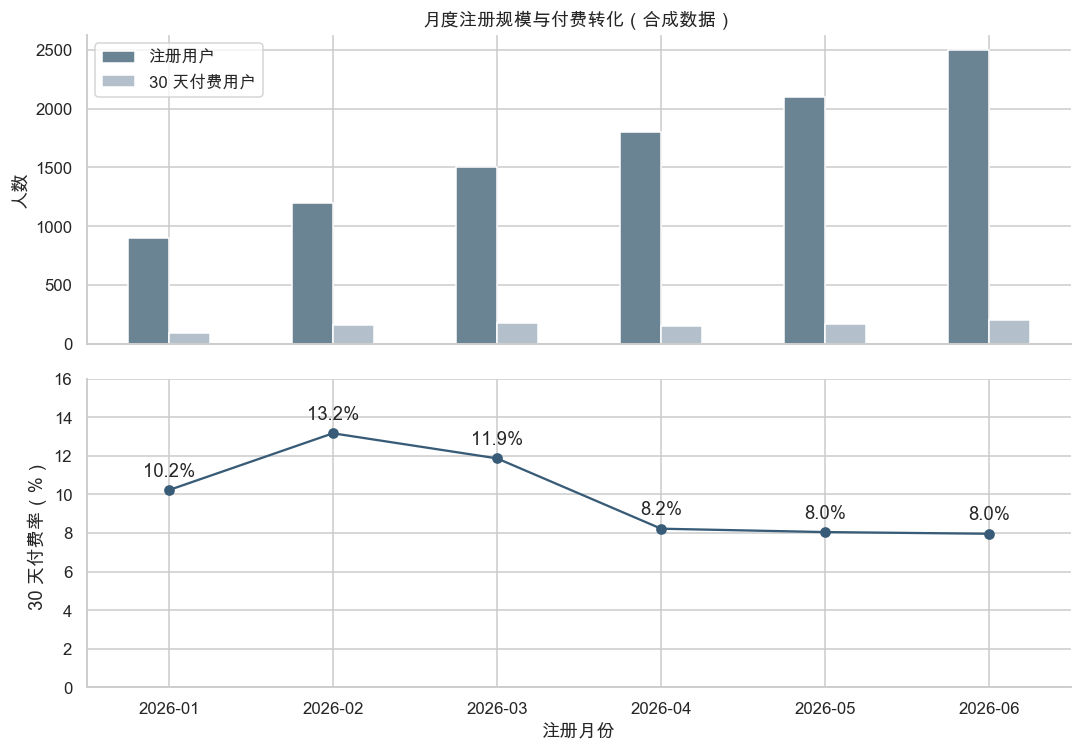

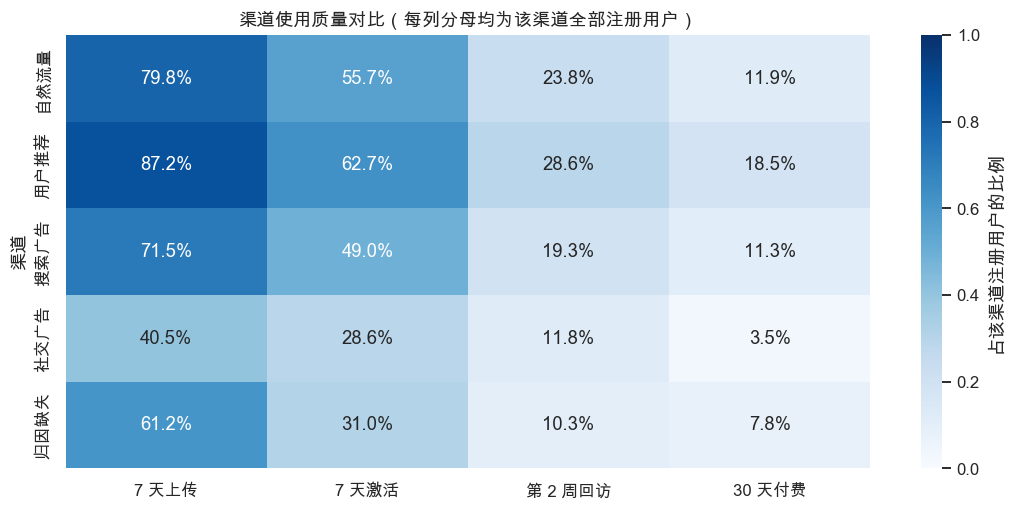

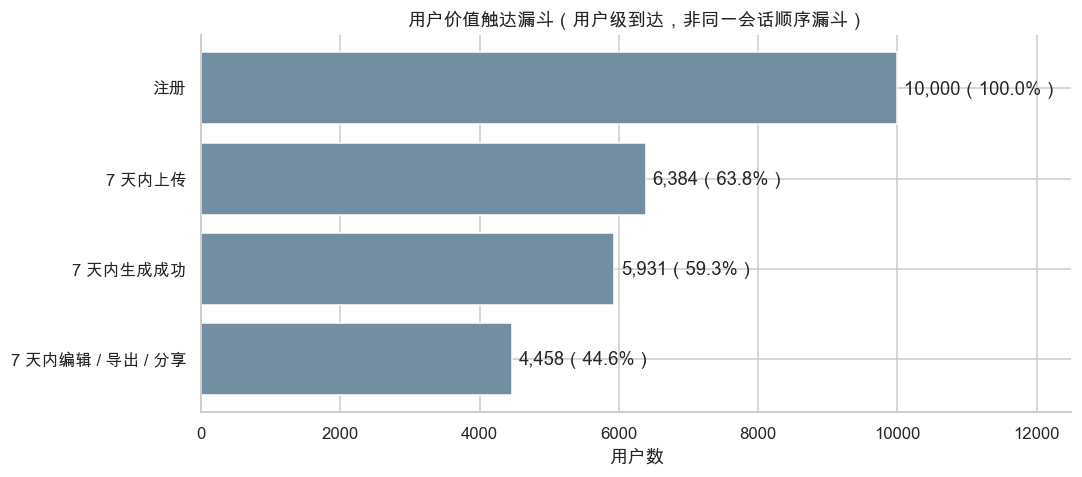

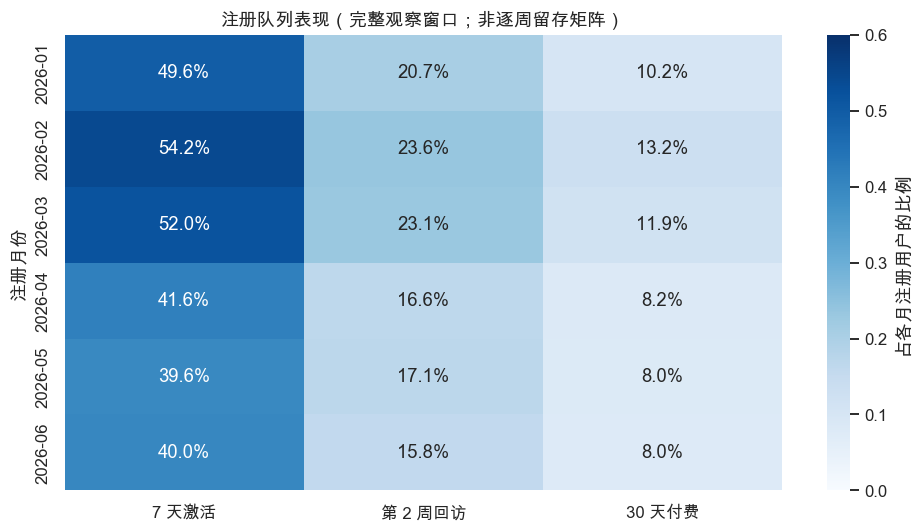

In [4]:
monthly=metrics.groupby('month').agg(users=('paid','size'),paid=('paid','sum'),activation=('activated','mean'),retention=('retained','mean'))
monthly['conversion']=monthly.paid/monthly.users
fig,ax=plt.subplots(2,1,figsize=(10,7),sharex=True)
monthly[['users','paid']].plot.bar(ax=ax[0],color=['#6b8494','#b3bfca'],rot=0)
ax[0].set(ylabel='人数',title='月度注册规模与付费转化（合成数据）')
ax[0].legend(['注册用户','30 天付费用户'])
ax[1].plot(range(6),monthly.conversion*100,marker='o',color='#385c77')
for i,v in enumerate(monthly.conversion): ax[1].annotate(f'{v:.1%}',(i,v*100),xytext=(0,9),textcoords='offset points',ha='center')
ax[1].set(ylabel='30 天付费率（%）',xlabel='注册月份',ylim=(0,16))
savefig('01_monthly_growth')

channel=metrics.groupby('channel').agg(n=('paid','size'),upload=('uploaded','mean'),activation=('activated','mean'),retention=('retained','mean'),paid=('paid','mean'))
fig,ax=plt.subplots(figsize=(10,4.8))
heat=channel[['upload','activation','retention','paid']].rename(index=CHANNELS,columns={'upload':'7 天上传','activation':'7 天激活','retention':'第 2 周回访','paid':'30 天付费'})
sns.heatmap(heat,annot=True,fmt='.1%',cmap='Blues',vmin=0,vmax=1,ax=ax,cbar_kws={'label':'占该渠道注册用户的比例'})
ax.set(title='渠道使用质量对比（每列分母均为该渠道全部注册用户）',xlabel='',ylabel='渠道')
savefig('02_channel_heatmap')

fig,ax=plt.subplots(figsize=(10,4.5))
stages=pd.Series([len(metrics),metrics.uploaded.sum(),metrics.succeeded.sum(),metrics.activated.sum()],index=['注册','7 天内上传','7 天内生成成功','7 天内编辑 / 导出 / 分享'])
ax.barh(stages.index,stages.values,color='#738da1'); ax.invert_yaxis()
for i,n in enumerate(stages): ax.text(n+100,i,f'{n:,}（{n/len(metrics):.1%}）',va='center')
ax.set(xlim=(0,12500),xlabel='用户数',title='用户价值触达漏斗（用户级到达，非同一会话顺序漏斗）')
savefig('03_activation_funnel')

fig,ax=plt.subplots(figsize=(9,5))
cohort=monthly[['activation','retention','conversion']].rename(columns={'activation':'7 天激活','retention':'第 2 周回访','conversion':'30 天付费'})
sns.heatmap(cohort,annot=True,fmt='.1%',vmin=0,vmax=.6,cmap='Blues',ax=ax,cbar_kws={'label':'占各月注册用户的比例'})
ax.set(title='注册队列表现（完整观察窗口；非逐周留存矩阵）',ylabel='注册月份',xlabel='')
savefig('04_cohort_heatmap')


## 4. 技术体验分布
这里的任务是首次上传及可能的重试，不代表完整使用历史。重复任务不是独立用户样本；箱线图仅展示分布，不进行独立性假设下的显著性检验。

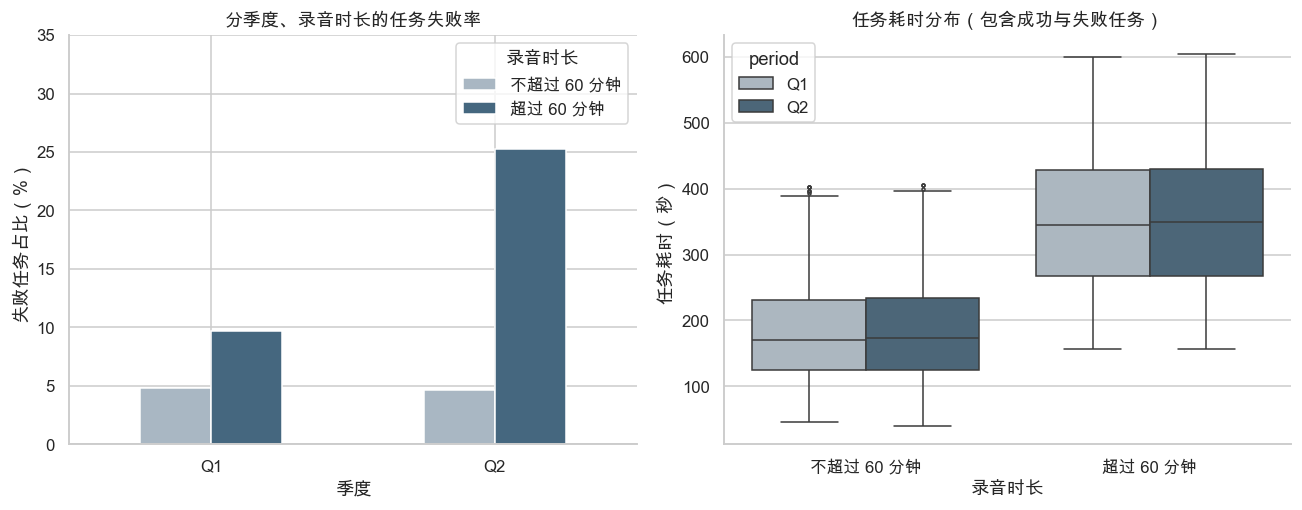

In [5]:
tasks=tasks.merge(users[['user_id','registered_at','period']],on='user_id')
tasks['age_days']=(tasks.started_at-tasks.registered_at).dt.total_seconds()/86400
tasks['length']=np.where(tasks.audio_minutes>60,'超过 60 分钟','不超过 60 分钟')
tasks['failed']=tasks.status.eq('failed').astype(int)
fig,ax=plt.subplots(1,2,figsize=(12,4.8))
failure=tasks.groupby(['period','length']).failed.mean().mul(100).unstack()
failure.plot.bar(ax=ax[0],rot=0,color=['#a9b7c3','#45677f'])
ax[0].set(title='分季度、录音时长的任务失败率',ylabel='失败任务占比（%）',xlabel='季度',ylim=(0,35));ax[0].legend(title='录音时长')
sns.boxplot(data=tasks,x='length',y='latency_seconds',hue='period',palette=['#a9b7c3','#45677f'],ax=ax[1],fliersize=2)
ax[1].set(title='任务耗时分布（包含成功与失败任务）',xlabel='录音时长',ylabel='任务耗时（秒）')
savefig('05_task_distributions')


## 5. 用户聚类：特征与选择方法

**聚类对象**：前 7 天有上传的用户。未上传用户没有任务时长或等待时间，将其作为已知业务状态单独统计，不把缺失任务特征补成 0 后强行参与聚类。

**输入特征**：前 7 天任务数、首次录音时长、首次任务耗时、首次任务失败与否、前 7 天是否激活。前三项用 log1p 降低偏态，然后所有特征标准化。

**不输入**：渠道、个人／团队标签、回访、支付、收入。聚类反映首次使用行为差异，不用于解释支付的因果机制。

**选 K**：比较 K=2…6 的轮廓系数；取最高值。轮廓系数使用固定的最多 2,500 人抽样，K-means 拟合全部上传用户。混合二元特征会明显影响欧氏距离，结果具有探索性质。

聚类用户 6,384 人；未上传用户 3,616 人单独列为未激活前置状态；选择 K=2


,k,silhouette,inertia
0,2,0.560333,22190.589992
1,3,0.403372,14731.308474
2,4,0.464205,9827.895506
3,5,0.508880,6689.136006
4,6,0.468971,5173.478047


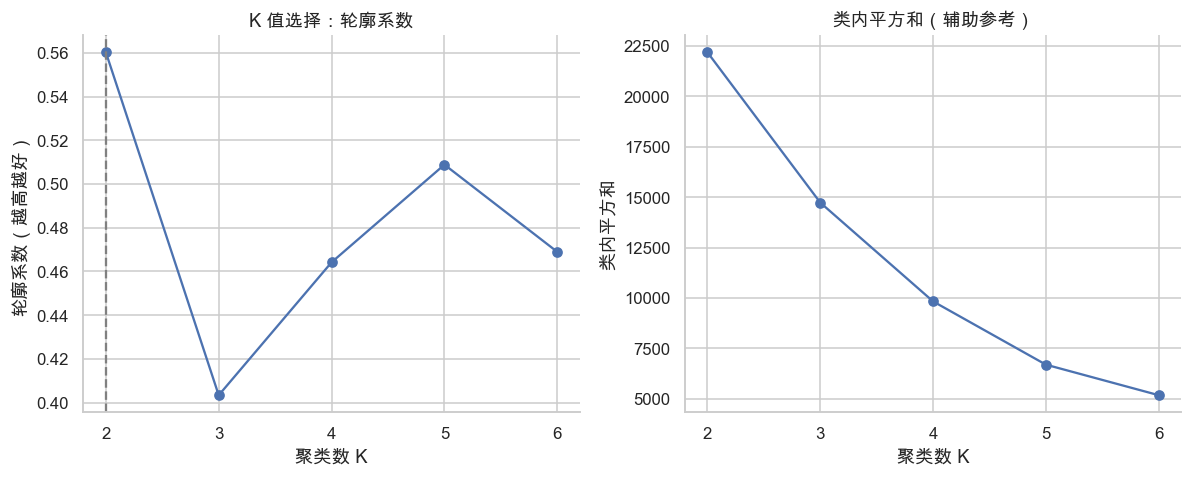

In [6]:
early_tasks=tasks[(tasks.age_days>=0)&(tasks.age_days<7)].sort_values(['started_at','task_id'])
first=early_tasks.drop_duplicates('user_id').set_index('user_id')
features=pd.DataFrame(index=first.index)
features['任务数']=early_tasks.groupby('user_id').size().reindex(first.index)
features['首次录音分钟']=first.audio_minutes
features['首次任务秒数']=first.latency_seconds
features['首次失败']=first.failed
features['7天激活']=metrics.activated.reindex(first.index)
assert not features.isna().any().any()
transformed=features.copy()
for c in ['任务数','首次录音分钟','首次任务秒数']: transformed[c]=np.log1p(transformed[c])
scaler=StandardScaler()
X=scaler.fit_transform(transformed)
assert np.isfinite(X).all() and np.abs(X).max()<20
sample_indices=np.random.RandomState(SEED).choice(len(X),min(2500,len(X)),replace=False)
sample_distances=cdist(X[sample_indices],X[sample_indices],metric='euclidean')
models={};scores=[]
for k in range(2,7):
    model=KMeans(n_clusters=k,init='random',n_init=100,random_state=SEED).fit(X)
    manual_inertia=np.square(X-model.cluster_centers_[model.labels_]).sum()
    assert np.isfinite(model.cluster_centers_).all() and np.isclose(manual_inertia,model.inertia_)
    score=silhouette_score(sample_distances,model.labels_[sample_indices],metric='precomputed')
    models[k]=model;scores.append({'k':k,'silhouette':score,'inertia':model.inertia_})
scores=pd.DataFrame(scores)
best_k=int(scores.loc[scores.silhouette.idxmax(),'k'])
model=models[best_k]
features['cluster']=model.labels_+1
print(f'聚类用户 {len(features):,} 人；未上传用户 {len(metrics)-len(features):,} 人单独列为未激活前置状态；选择 K={best_k}')
display(scores)
fig,ax=plt.subplots(1,2,figsize=(11,4.5))
ax[0].plot(scores.k,scores.silhouette,marker='o');ax[0].axvline(best_k,color='gray',linestyle='--')
ax[0].set(title='K 值选择：轮廓系数',xlabel='聚类数 K',ylabel='轮廓系数（越高越好）',xticks=scores.k)
ax[1].plot(scores.k,scores.inertia,marker='o')
ax[1].set(title='类内平方和（辅助参考）',xlabel='聚类数 K',ylabel='类内平方和',xticks=scores.k)
savefig('06_cluster_selection')


## 6. 聚类可视化与群体画像
PCA 只用来把五维特征投影成二维图，不用于拟合聚类。点的重叠可能来自投影丢失信息；图中每类均为中性编号，不预设“高价值用户”等结论。

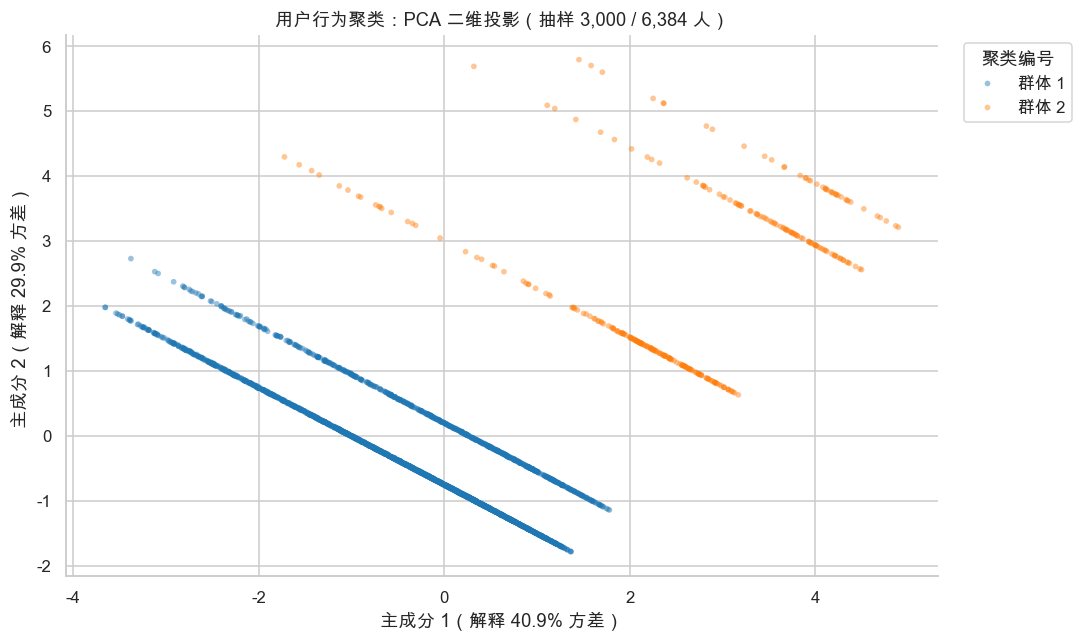

,人数,任务数,首次录音分钟,首次任务秒数,首次失败,7天激活
cluster,,,,,,
1,5694,1.000,50.634,247.969,0.0,0.751
2,690,1.391,68.514,309.141,1.0,0.262


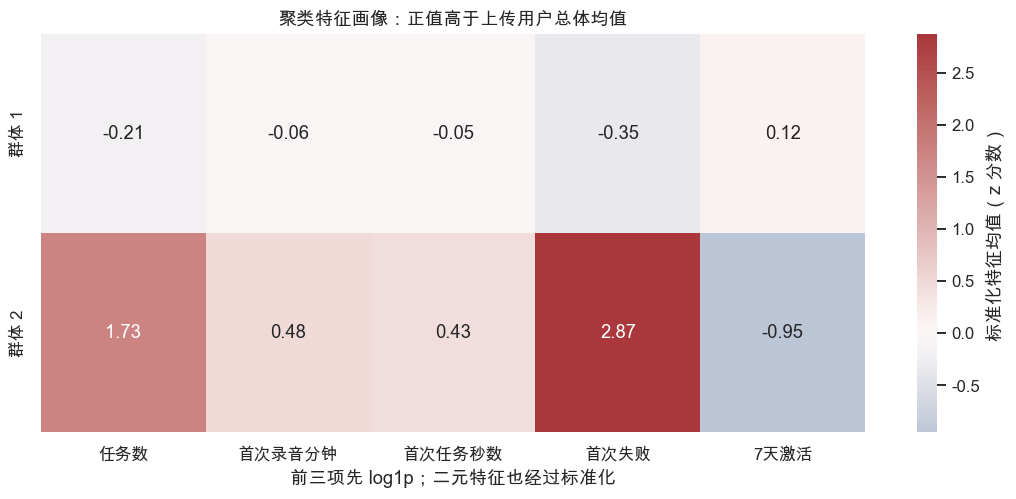

相同数据、不同初始化的 ARI： [1. 1. 1.]
这里只检验初始化稳定性，不代表跨样本、跨时间或真实数据的稳定性。
聚类与首次失败规则的 ARI： 1.0
本次聚类完全重现首次成功 / 首次失败规则，没有提供超出简单规则的新分群。应优先采用可解释的规则，不将此结果包装成新发现的市场客群。


In [7]:
pca=PCA(n_components=2,svd_solver='full')
pca.fit(X)
coords=np.einsum('ij,kj->ik',X-pca.mean_,pca.components_,optimize=False)
assert np.isfinite(coords).all()
scatter=pd.DataFrame(coords,columns=['PC1','PC2'],index=features.index)
scatter['群体']='群体 '+features.cluster.astype(str)
sample=scatter.sample(min(3000,len(scatter)),random_state=SEED)
fig,ax=plt.subplots(figsize=(10,6))
sns.scatterplot(data=sample,x='PC1',y='PC2',hue='群体',palette='tab10',alpha=.45,s=14,linewidth=0,ax=ax)
ax.set(title=f'用户行为聚类：PCA 二维投影（抽样 {len(sample):,} / {len(features):,} 人）',
       xlabel=f'主成分 1（解释 {pca.explained_variance_ratio_[0]:.1%} 方差）',ylabel=f'主成分 2（解释 {pca.explained_variance_ratio_[1]:.1%} 方差）')
ax.legend(title='聚类编号',bbox_to_anchor=(1.02,1),loc='upper left')
savefig('07_cluster_pca')

profile=features.groupby('cluster').mean()
profile.insert(0,'人数',features.groupby('cluster').size())
display(profile.round(3))
standardized=pd.DataFrame(X,index=features.index,columns=transformed.columns)
standardized['cluster']=features.cluster
centers=standardized.groupby('cluster').mean()
centers.index=['群体 '+str(x) for x in centers.index]
fig,ax=plt.subplots(figsize=(10,4+best_k*.35))
sns.heatmap(centers,annot=True,fmt='.2f',center=0,cmap='vlag',ax=ax,cbar_kws={'label':'标准化特征均值（z 分数）'})
ax.set(title='聚类特征画像：正值高于上传用户总体均值',ylabel='',xlabel='前三项先 log1p；二元特征也经过标准化')
savefig('08_cluster_profiles')

ari=[]
for seed in [7,42,123]:
    other=KMeans(n_clusters=best_k,init='random',n_init=100,random_state=seed).fit_predict(X)
    ari.append(adjusted_rand_score(model.labels_,other))
print('相同数据、不同初始化的 ARI：',np.round(ari,4))
print('这里只检验初始化稳定性，不代表跨样本、跨时间或真实数据的稳定性。')
rule_ari=adjusted_rand_score(features['首次失败'],features.cluster)
print('聚类与首次失败规则的 ARI：',rule_ari)
if rule_ari==1:
    print('本次聚类完全重现首次成功 / 首次失败规则，没有提供超出简单规则的新分群。应优先采用可解释的规则，不将此结果包装成新发现的市场客群。')


## 7. 聚类后的结果比较（不把结果当输入）
回访比较使用各群体全体用户；未来付费比较仅使用第 7 天仍未付费者作为风险集，观察 [7,30) 天首次成功支付。这样避免前 7 天已经付费用户被重复纳入新增付费分母。

误差线为 Wilson 95% 区间，不进行多重比较显著性宣称。分组由同一份数据探索得到，群体差异不能解释为因果效应。

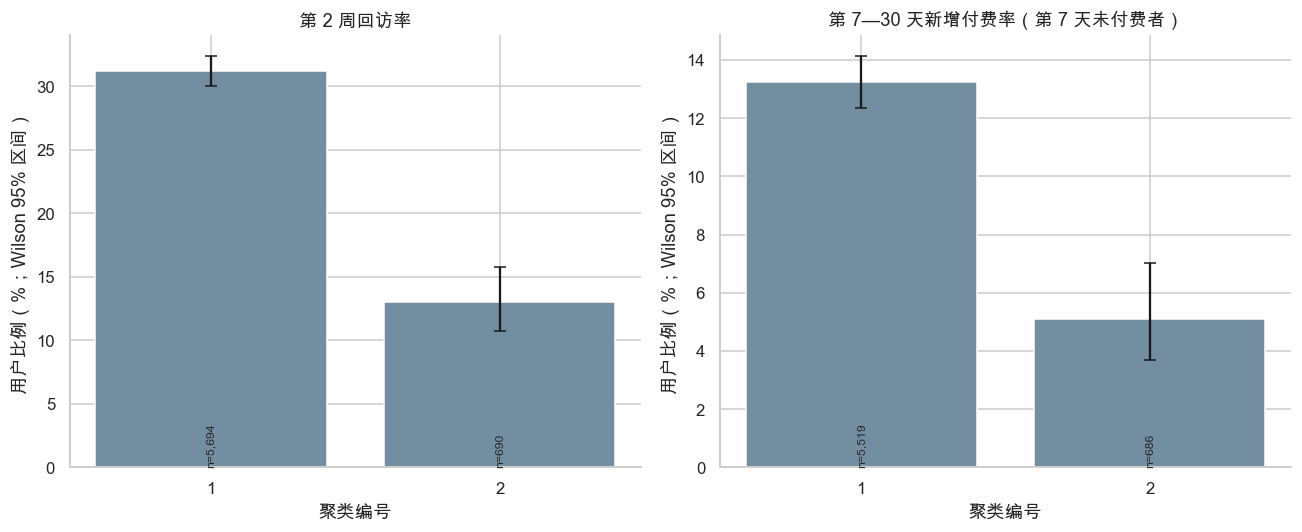

,n,returned,at_risk,later_paid,return_rate,late_pay_rate
cluster,,,,,,
1,5694,1777,5519,730,0.3121,0.1323
2,690,90,686,35,0.1304,0.0510


1619

In [8]:
joined=metrics.join(features[['cluster']],how='inner')
outcomes=joined.groupby('cluster').agg(n=('retained','size'),returned=('retained','sum'))
at_risk=joined[joined.early_paid==0].groupby('cluster').agg(at_risk=('later_paid','size'),later_paid=('later_paid','sum'))
outcomes=outcomes.join(at_risk)
outcomes['return_rate']=outcomes.returned/outcomes.n
outcomes['late_pay_rate']=outcomes.later_paid/outcomes.at_risk
def wilson(k,n):
    p=k/n;z=1.96;d=1+z*z/n
    mid=(p+z*z/(2*n))/d
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return mid-half,mid+half
fig,ax=plt.subplots(1,2,figsize=(12,5))
for axis,num_col,den_col,title in [(ax[0],'returned','n','第 2 周回访率'),(ax[1],'later_paid','at_risk','第 7—30 天新增付费率（第 7 天未付费者）')]:
    rate=outcomes[num_col]/outcomes[den_col]
    lo,hi=wilson(outcomes[num_col],outcomes[den_col])
    axis.bar(outcomes.index.astype(str),rate*100,yerr=np.array([rate-lo,hi-rate])*100,capsize=4,color='#738da1')
    for i,(value,n) in enumerate(zip(rate,outcomes[den_col])):
        axis.text(i,0,f'n={n:,}',ha='center',va='bottom',fontsize=8,rotation=90)
    axis.set(title=title,xlabel='聚类编号',ylabel='用户比例（%；Wilson 95% 区间）')
savefig('09_cluster_outcomes')
display(outcomes.round(4))
features.to_csv(ROOT/'data'/'cluster_assignments.csv',encoding='utf-8-sig')
profile.to_csv(ROOT/'data'/'cluster_profiles.csv',encoding='utf-8-sig')
outcomes.to_csv(ROOT/'data'/'cluster_outcomes.csv',encoding='utf-8-sig')
summary={'n_clustered':len(features),'n_excluded':len(metrics)-len(features),'best_k':best_k,
 'silhouette':float(scores.silhouette.max()),'pca_variance':pca.explained_variance_ratio_.tolist(),
 'initialization_ari':ari,'rule_ari':rule_ari,'profiles':profile.reset_index().to_dict('records'),
 'outcomes':outcomes.reset_index().to_dict('records'),'scores':scores.to_dict('records')}
(ROOT/'clustering.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))


## 8. 解释与下一步

1. 结合人数、原始单位画像和结果图理解各群体，不只根据二维点云命名人群。
2. 任务次数最大只有 2，聚类不是“使用频次分层”；前 7 天激活与首次失败是较强的二元特征，部分分组可能只是这些规则的重现。
3. 可将聚类作为选择访谈样本的工具：覆盖短／长任务、成功／失败、激活／未激活等组合，而不直接决定营销资源分配。
4. 真实业务应增加跨周使用频次、编辑幅度、分享接收、团队协作等观测；在新时间段验证群体稳定性，并比较规则分群与聚类是否产生不同的行动建议。
5. 未上传用户需独立调查；不应被本聚类覆盖率掩盖。反馈文本只有少数模板，不适合包装为文本语义聚类项目。

本 Notebook 保存了运行输出与图表；所有结果可以从原始 CSV 重算。